# Allele Frequencies, Hardy-Weinberg Equilibrium and FST with NumPy

**Question:** if two populations differ at a few genetic loci, can we find those loci from genotype data alone?

This notebook builds the three core population-genetics calculations from scratch with NumPy:

1. **Allele frequency** at each locus
2. **Hardy-Weinberg equilibrium (HWE)** test (a quality-control check)
3. **FST**, a measure of how differentiated two populations are at each locus

**Data note:** all data here is **simulated** with a known answer (six loci are deliberately made different between the two populations). That lets us check whether the method recovers what we planted. It is not real sequencing data.

## Concepts

For a biallelic locus with alternate-allele frequency $p$ and reference-allele frequency $q = 1 - p$:

- **Hardy-Weinberg expectation** for genotype frequencies (random mating, no selection, large population): $q^2$ (0 copies), $2pq$ (1 copy), $p^2$ (2 copies).
- **Expected heterozygosity:** $H = 2p(1-p)$.
- **FST** (here in Nei's $G_{ST}$ form): $F_{ST} = \dfrac{H_T - H_S}{H_T}$, where $H_S$ is the average heterozygosity within each population and $H_T$ is the heterozygosity of the pooled populations. FST is 0 when populations have the same allele frequency and approaches 1 when they are fixed for different alleles.

Genotypes are coded as the **number of alternate alleles** (0, 1 or 2).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(42)   # fixed seed so results are reproducible

## 1. Simulate two populations

Both populations start from the same baseline allele frequencies. At six chosen loci, population B is shifted by 0.3, which creates real differentiation.

In [2]:
n_loci = 60          # number of biallelic loci (think: SNPs)
n_per_pop = 120      # diploid individuals per population

p_base = rng.uniform(0.1, 0.9, size=n_loci)       # shared baseline frequencies
diff_loci = np.array([5, 12, 23, 31, 44, 52])      # loci we deliberately differentiate

p_A = p_base.copy()
p_B = p_base.copy()
# shift toward the middle so frequencies stay inside (0, 1)
p_B[diff_loci] = np.where(p_base[diff_loci] > 0.5,
                          p_base[diff_loci] - 0.3,
                          p_base[diff_loci] + 0.3)

# each diploid genotype = number of alternate alleles out of 2 draws
geno_A = rng.binomial(2, p_A, size=(n_per_pop, n_loci))
geno_B = rng.binomial(2, p_B, size=(n_per_pop, n_loci))

print("Genotype matrix shape (individuals x loci):", geno_A.shape)
print("First 3 individuals, first 8 loci (pop A):\n", geno_A[:3, :8])

Genotype matrix shape (individuals x loci): (120, 60)
First 3 individuals, first 8 loci (pop A):
 [[1 1 2 1 0 2 1 2]
 [1 1 2 2 0 2 2 2]
 [1 2 2 2 1 2 2 2]]


## 2. Allele frequency

With genotypes coded 0/1/2, the alternate-allele frequency is the mean genotype divided by 2 (each individual carries 2 alleles).

In [3]:
def allele_freq(geno):
    """Alternate-allele frequency at each locus (genotypes coded 0/1/2)."""
    return geno.mean(axis=0) / 2

pA_hat = allele_freq(geno_A)
pB_hat = allele_freq(geno_B)

print("Estimated vs true frequency, first 5 loci (pop A):")
print(np.round(np.column_stack([pA_hat[:5], p_A[:5]]), 3))
print("Mean absolute estimation error (pop A): %.4f" % np.abs(pA_hat - p_A).mean())

Estimated vs true frequency, first 5 loci (pop A):
[[0.721 0.719]
 [0.442 0.451]
 [0.796 0.787]
 [0.654 0.658]
 [0.179 0.175]]
Mean absolute estimation error (pop A): 0.0203


## 3. Hardy-Weinberg test

We compare observed genotype counts to the HWE expectation with a chi-square test (1 degree of freedom: 3 genotype classes, minus 1, minus 1 for the estimated allele frequency). Because our simulation mates at random by construction, only about 5% of loci should fail at $p < 0.05$ by chance.

In [4]:
def hwe_chi_square(geno):
    """Chi-square statistic and p-value for Hardy-Weinberg at each locus."""
    n = geno.shape[0]
    p = allele_freq(geno)
    q = 1 - p
    observed = np.stack([(geno == 0).sum(axis=0),
                         (geno == 1).sum(axis=0),
                         (geno == 2).sum(axis=0)])
    expected = np.stack([q**2, 2 * p * q, p**2]) * n
    with np.errstate(divide="ignore", invalid="ignore"):
        terms = np.where(expected > 0, (observed - expected) ** 2 / expected, 0.0)
    stat = terms.sum(axis=0)
    return stat, chi2.sf(stat, df=1)

_, pval_A = hwe_chi_square(geno_A)
_, pval_B = hwe_chi_square(geno_B)
print("Loci failing HWE at p < 0.05 (pop A): %d of %d" % ((pval_A < 0.05).sum(), n_loci))
print("Loci failing HWE at p < 0.05 (pop B): %d of %d" % ((pval_B < 0.05).sum(), n_loci))
print("Expected by chance alone: about %.1f per population" % (0.05 * n_loci))

Loci failing HWE at p < 0.05 (pop A): 1 of 60
Loci failing HWE at p < 0.05 (pop B): 2 of 60
Expected by chance alone: about 3.0 per population


## 4. FST per locus

Then we rank loci by FST and check whether the top hits are the six loci we planted.

In [5]:
def fst_two_pops(p1, p2):
    """Per-locus FST (Nei's G_ST form) for two equally sized populations."""
    p_bar = (p1 + p2) / 2
    h_s = (2 * p1 * (1 - p1) + 2 * p2 * (1 - p2)) / 2
    h_t = 2 * p_bar * (1 - p_bar)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(h_t > 0, (h_t - h_s) / h_t, 0.0)

fst = fst_two_pops(pA_hat, pB_hat)

top = np.argsort(fst)[::-1][:len(diff_loci)]
recovered = sorted(set(top.tolist()) & set(diff_loci.tolist()))

print("Mean FST across all loci: %.4f" % fst.mean())
print("Top %d loci by FST:        %s" % (len(diff_loci), sorted(top.tolist())))
print("Loci we planted:           %s" % sorted(diff_loci.tolist()))
print("Recovered %d of %d planted loci: %s" % (len(recovered), len(diff_loci), recovered))

Mean FST across all loci: 0.0128
Top 6 loci by FST:        [5, 12, 23, 31, 44, 52]
Loci we planted:           [5, 12, 23, 31, 44, 52]
Recovered 6 of 6 planted loci: [5, 12, 23, 31, 44, 52]


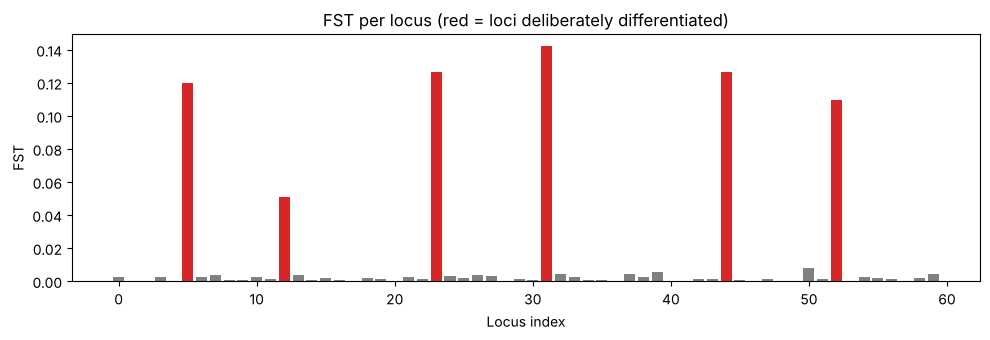

In [6]:
colors = np.where(np.isin(np.arange(n_loci), diff_loci), "tab:red", "tab:gray")
plt.figure(figsize=(10, 3.5))
plt.bar(np.arange(n_loci), fst, color=colors)
plt.xlabel("Locus index")
plt.ylabel("FST")
plt.title("FST per locus (red = loci deliberately differentiated)")
plt.tight_layout()
plt.show()

## Check your understanding

Try to answer these in your own words before moving on (write your answers in a new markdown cell):

1. Why is allele frequency the mean genotype divided by 2, not just the mean?
2. Why do we expect about 3 loci to fail the HWE test even though the simulation obeys HWE?
3. What would happen to FST if both populations had identical allele frequencies? What if they were fixed for opposite alleles?
4. Which loci, if any, did the FST ranking miss, and what might explain that (hint: sample size and sampling noise)?

## Limitations

- Nei's $G_{ST}$ form is biased upward for small samples; published studies typically use the Weir-Cockerham or Hudson estimators.
- Real data has missing genotypes, linkage between loci, and population structure within groups. None of that is modeled here.
- Simulated data shows the method works on a clean case. It is not evidence about any real population.